# UR Fall 期末專案成果

實驗：真實 UR Fall camera 0 RGB；ST-GCN 特徵＋正常資料 AE。這本 Notebook **只讀正式輸出**，不訓練、不校準、不重新推論 Test。缺檔、hash、切分或分母不一致會報錯。

歷史 Test 已查看，以下為固定切分工程對照；不是未見過的獨立測試。教師尚未明定評估單位等細節，不換算課程分數。影片層級命中不代表起跌警示時間正確。

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from fall_detect.evaluation.course_report import load_course_results
from fall_detect.io_utils import read_json
from fall_detect.config import project_path

result = load_course_results()
m = result['test']['metrics']
print('Python:', sys.executable)
print('Run:', result['run'].name)
print('Recipe hash:', m['recipe_hash'])
print('Split hash:', m['split_hash'])
print('AE SHA256:', m['artifact_hashes']['autoencoder.pt'])
print('所有正式數字／事件／來源 hash 已核對')

def table(headers, rows):
    display(Markdown('| ' + ' | '.join(headers) + ' |\n| ' + ' | '.join(['---'] * len(headers)) + ' |\n' + '\n'.join('| ' + ' | '.join(str(x) for x in row) + ' |' for row in rows)))
def pct(value):
    return '未定義' if value is None else f'{value:.2%}'


Python: C:\成大專案\fall-detection-anomaly\.venv\Scripts\python.exe
Run: course-ur-balanced-001
Recipe hash: 745c11321bbc5d61e70d2ab1474438f8363c96eb6d26b175829a0d302b9584e2
Split hash: 0b9a0f0cf3609c478afcbbe028130c7d519e26b573135fbd739c074c68bc93c5
AE SHA256: af38f41eac11c2ec805ec8c13be0f3db8bc9d3a94da5e1ec8d8a9dcac3902fa7
所有正式數字／事件／來源 hash 已核對


## 1. 資料切分與方法

原始序列先切分，沒有重切。Scaler／AE只讀 Train ADL；正常Validation選checkpoint，完整Validation選門檻與候選。YOLO11m Pose是預訓練模型，映射OpenPose18後取凍結Kinetics ST-GCN分類頭前256D。AE重建誤差不是跌倒機率，不輸出七類動作。

30 fps／30幀窗口／stride5；連續3個有效窗口分數均大於門檻才確認事件。缺少合法連續分數為unknown，不能視為正常。未保證人物隔離。

In [2]:
sources = result['split']['sequences']
table(['Split', 'ADL', 'Fall', '用途'], [[s, sum(r['split']==s and r['label']==0 for r in sources), sum(r['split']==s and r['label']==1 for r in sources), use] for s,use in [('train','Scaler / AE'),('validation','checkpoint / threshold / selection'),('test','frozen engineering comparison')]])
sampling = result['sources']['training_sampling']
counts = sampling['train_normal_feature_counts']
print('Train ADL:', len(counts), 'sequences /', sum(counts.values()), 'windows')
print('每序列有效窗範圍:', min(counts.values()), '-', max(counts.values()))
print('正常 Validation 特徵來源:', len(result['sources']['val_normal_feature_hashes']))
print('真實預訓練權重來源:')
table(['Role','Source','SHA256'], [[role,w['source_page'],w['sha256']] for role,w in result['sources']['weights'].items()])


| Split | ADL | Fall | 用途 |
| --- | --- | --- | --- |
| train | 24 | 0 | Scaler / AE |
| validation | 8 | 15 | checkpoint / threshold / selection |
| test | 8 | 15 | frozen engineering comparison |

Train ADL: 24 sequences / 659 windows
每序列有效窗範圍: 9 - 55
正常 Validation 特徵來源: 8
真實預訓練權重來源:


| Role | Source | SHA256 |
| --- | --- | --- |
| pose | https://github.com/ultralytics/assets/releases/tag/v8.3.0 | 9ed4d6879c271b554149ea93ec71c9531da17863a64e0e80945d9c11c668ad3d |
| stgcn | https://github.com/yysijie/st-gcn/blob/221c0e152054b8da593774c0d483e59befdb9061/OLD_README.md | 12c56ed5535dd28a075e7d04dec96f572f8b1dc87548004761157e15b7d9e12e |

## 2. Loss 與事前鎖定候選

三候選最多100 epochs、patience10。窗口等權32維latent／序列均衡32維／序列均衡16維。門檻選Validation balanced sequence accuracy；候選依operational accuracy、F1、全體跌倒召回、較少FP、較早候選排序。Test後停止調參。

Loss是MSE，不是Accuracy。CUDA曾有CuBLAS決定性警告，保留實際hash；不承諾重新訓練逐位元一致。

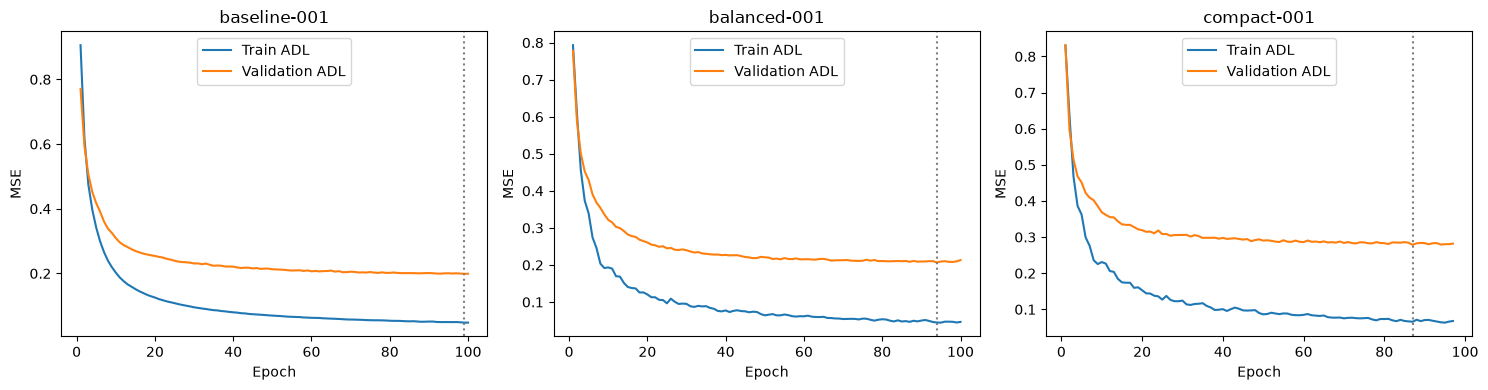

| Run | Epochs | Best epoch | Threshold | Val all accuracy | Val F1 | TP/TN/FP/FN |
| --- | --- | --- | --- | --- | --- | --- |
| course-ur-baseline-001 | 100 | 99 | 0.485934 | 65.22% | 66.67% | 8/7/1/7 |
| course-ur-balanced-001 | 100 | 94 | 0.335563 | 69.57% | 75.86% | 11/5/3/4 |
| course-ur-compact-001 | 97 | 87 | 0.674850 | 60.87% | 60.87% | 7/7/1/8 |

凍結後選定: course-ur-balanced-001


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, history) in zip(axes, result['history'].items()):
    epochs = [int(r['epoch']) for r in history]
    train = [float(r['train_loss']) for r in history]
    val = [float(r['val_normal_loss']) for r in history]
    best = int(np.argmin(val))
    ax.plot(epochs, train, label='Train ADL')
    ax.plot(epochs, val, label='Validation ADL')
    ax.axvline(epochs[best], color='gray', linestyle=':')
    ax.set(title=name.replace('course-ur-', ''), xlabel='Epoch', ylabel='MSE')
    ax.legend()
plt.tight_layout()
plt.show()
rows=[]
for c in result['freeze']['candidates']:
    v=c['validation_metrics']
    h=result['history'][c['run']]
    rows.append([c['run'], len(h), min(h,key=lambda r:float(r['val_normal_loss']))['epoch'], f"{c['threshold']:.6f}", pct(v['operational_accuracy']), pct(v['sequence_fall_f1']), f"{v['TP']}/{v['TN']}/{v['FP']}/{v['FN']}"])
table(['Run','Epochs','Best epoch','Threshold','Val all accuracy','Val F1','TP/TN/FP/FN'],rows)
print('凍結後選定:', result['freeze']['selected_run'])


## 3. 正式 UR Test 成績與分母

二元指標只計可判定影片。另列unknown、coverage、全體正確率及全體跌倒召回，不能只挑較高數字。一次確認事件就將整支影片判陽性，可能來自跌倒前誤报；未量測精確警示時機。

| 指標 | 值 | 分母／公式 |
| --- | --- | --- |
| Accuracy（可判定） | 50.00% | 11/22 |
| Precision（可判定） | 63.64% | 7/11 |
| Recall（可判定Fall） | 50.00% | 7/14 |
| F1（可判定） | 56.00% | 14/(14+4+7) |
| 全體 operational accuracy | 47.83% | 11/23 |
| 全體 Fall recall | 46.67% | 7/15 |
| Sequence coverage | 95.65% | 22/23 |
| Unknown | 1 | n_total=23; n_evaluable=22 |
| Window coverage | 69.39% | 有效端點／全部排程端點 |

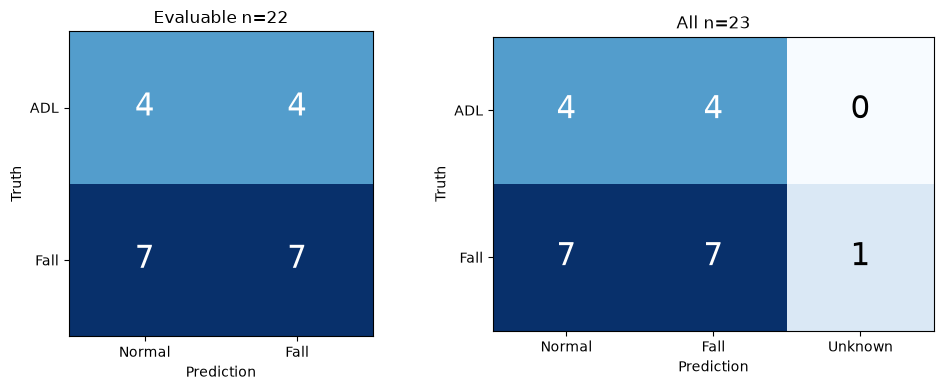

In [4]:
tp,tn,fp,fn=[m[k] for k in ('TP','TN','FP','FN')]
table(['指標','值','分母／公式'],[
 ['Accuracy（可判定）',pct(m['sequence_accuracy']),f'{tp+tn}/{m["n_evaluable"]}'],
 ['Precision（可判定）',pct(m['sequence_fall_precision']),f'{tp}/{tp+fp}'],
 ['Recall（可判定Fall）',pct(m['sequence_fall_recall']),f'{tp}/{tp+fn}'],
 ['F1（可判定）',pct(m['sequence_fall_f1']),f'{2*tp}/({2*tp}+{fp}+{fn})'],
 ['全體 operational accuracy',pct(m['operational_accuracy']),f'{tp+tn}/{m["n_total"]}'],
 ['全體 Fall recall',pct(m['end_to_end_fall_recall']),f'{tp}/{m["by_class"]["Fall"]["n_total"]}'],
 ['Sequence coverage',pct(m['sequence_coverage']),f'{m["n_evaluable"]}/{m["n_total"]}'],
 ['Unknown',m['n_unknown'],f'n_total={m["n_total"]}; n_evaluable={m["n_evaluable"]}'],
 ['Window coverage',pct(m['window_coverage']),'有效端點／全部排程端點']])
fig, axes=plt.subplots(1,2,figsize=(10,4))
outcomes=np.array(m['outcomes_with_unknown'])
for ax,values,labels,title in [(axes[0],outcomes[:,:2],['Normal','Fall'],f'Evaluable n={m["n_evaluable"]}'),(axes[1],outcomes,['Normal','Fall','Unknown'],f'All n={m["n_total"]}')]:
    ax.imshow(values,cmap='Blues',vmin=0)
    for (r,c), value in np.ndenumerate(values):
        ax.text(c,r,str(value),ha='center',va='center',fontsize=22,color='white' if value>values.max()/2 else 'black')
    ax.set(xticks=range(len(labels)),xticklabels=labels,yticks=[0,1],yticklabels=['ADL','Fall'],xlabel='Prediction',ylabel='Truth',title=title)
plt.tight_layout(); plt.show()


## 4. 與既有混合模型分開比較

相同23支UR Test，舊模型Train混合UR／Le2i／CAUCA，新模型Train只用UR ADL。舊門檻與run原封保留。樣本小且Test曾查看，這是工程對照；改善不能解讀成未知場景可靠度。

In [5]:
table(['Model','UR TP/TN/FP/FN/U','Accuracy evaluable','F1 evaluable','Accuracy all','Fall recall all'], [[name, '/'.join(str(v[k]) for k in ('TP','TN','FP','FN','n_unknown')),pct(v['sequence_accuracy']),pct(v['sequence_fall_f1']),pct(v['operational_accuracy']),pct(v['end_to_end_fall_recall'])] for name,v in [('Mixed historical',result['mixed_ur']),('UR-only selected',m)]])
print('整體正確支數差:', (m['TP']+m['TN'])-(result['mixed_ur']['TP']+result['mixed_ur']['TN']))
print('誤報支數差:', m['FP']-result['mixed_ur']['FP'])


| Model | UR TP/TN/FP/FN/U | Accuracy evaluable | F1 evaluable | Accuracy all | Fall recall all |
| --- | --- | --- | --- | --- | --- |
| Mixed historical | 3/7/1/11/1 | 45.45% | 33.33% | 43.48% | 20.00% |
| UR-only selected | 7/4/4/7/1 | 50.00% | 56.00% | 47.83% | 46.67% |

整體正確支數差: 1
誤報支數差: 3


## 5. 錯誤案例與警示時間

以下完整列出23支Test，不用剪輯或截圖反推成績。first_alarm是影片中的確認時間，並非已驗證的起跌延遲。unknown影片保留其原始標籤及原因。展示影片另選Validation正常、跌倒、誤報與漏報，僅用來解釋行為。

In [6]:
table(['Sequence','Truth','Prediction','Sequence score','First alarm (s)','Window coverage','Reason'],[[r['sequence_id'],r['label'],'unknown' if r['prediction'] is None else r['prediction'],'—' if r['sequence_score'] is None else f"{r['sequence_score']:.4f}",'—' if r['first_alarm_ms'] is None else f"{r['first_alarm_ms']/1000:.2f}",pct(r['window_coverage']),r['unknown_reason'] or ''] for r in result['test']['rows']])
print('錯誤／unknown案例:', [r['sequence_id'] for r in result['test']['rows'] if r['prediction'] != r['label']])
diagnosis=read_json(project_path('docs/validation/course-ur-window-diagnosis.json'))
table(['Validation case','Valid features','Legal event windows','No-person raw frames','Unique tracks','Prediction'],[[r['sequence_id'],r['valid_features'],r['legal_event_windows'],r['frames_without_person'],len(r['raw_track_ids']),r['prediction']] for r in diagnosis['rows'] if r['split']=='validation' and r['sequence_id'] in ['adl-04','adl-20','fall-02','fall-19']])


| Sequence | Truth | Prediction | Sequence score | First alarm (s) | Window coverage | Reason |
| --- | --- | --- | --- | --- | --- | --- |
| adl-13 | 0 | 0 | 0.2847 | — | 70.21% |  |
| adl-15 | 0 | 1 | 0.3520 | 8.97 | 70.00% |  |
| adl-39 | 0 | 0 | 0.1928 | — | 63.27% |  |
| adl-03 | 0 | 1 | 1.4457 | 3.80 | 100.00% |  |
| adl-34 | 0 | 1 | 0.8100 | 3.47 | 60.61% |  |
| adl-02 | 0 | 0 | 0.3064 | — | 80.65% |  |
| adl-14 | 0 | 1 | 0.3473 | 6.80 | 80.49% |  |
| adl-09 | 0 | 0 | 0.2921 | — | 100.00% |  |
| fall-10 | 1 | 1 | 1.1614 | 1.30 | 42.86% |  |
| fall-27 | 1 | 0 | 0.0628 | — | 76.92% |  |
| fall-04 | 1 | 1 | 0.4491 | 1.30 | 21.43% |  |
| fall-23 | 1 | 0 | 0.1321 | — | 50.00% |  |
| fall-15 | 1 | 0 | 0.1839 | — | 66.67% |  |
| fall-21 | 1 | 0 | 0.1036 | — | 66.67% |  |
| fall-20 | 1 | 1 | 1.3084 | 1.30 | 58.82% |  |
| fall-12 | 1 | 1 | 1.3297 | 1.30 | 100.00% |  |
| fall-03 | 1 | 1 | 0.9183 | 5.80 | 63.16% |  |
| fall-01 | 1 | 0 | 0.3019 | — | 62.96% |  |
| fall-26 | 1 | 1 | 0.5117 | 1.30 | 42.86% |  |
| fall-28 | 1 | 1 | 0.3547 | 1.63 | 62.50% |  |
| fall-24 | 1 | unknown | — | — | 28.57% | no_legal_event_score |
| fall-05 | 1 | 0 | 0.1960 | — | 64.00% |  |
| fall-17 | 1 | 0 | 0.1050 | — | 78.57% |  |

錯誤／unknown案例: ['adl-15', 'adl-03', 'adl-34', 'adl-14', 'fall-27', 'fall-23', 'fall-15', 'fall-21', 'fall-01', 'fall-24', 'fall-05', 'fall-17']


| Validation case | Valid features | Legal event windows | No-person raw frames | Unique tracks | Prediction |
| --- | --- | --- | --- | --- | --- |
| adl-20 | 30 | 26 | 32 | 14 | 1 |
| adl-04 | 24 | 22 | 0 | 1 | 0 |
| fall-19 | 5 | 3 | 42 | 7 | 0 |
| fall-02 | 9 | 7 | 3 | 11 | 1 |

## 6. 限制與重現

- 現有結果未達課程UR參考Accuracy90%／F1 0.87，且官方切分與unknown規則尚未確認，不能直接換算分數。
- 程式功能通過、Notebook數字吻合、畫面清楚，都不代表辨識品質足夠。骨架追蹤／時間窗失效及正常與跌倒分數重疊仍存在。
- 歷史Test已查看；不以重新切分或新run名稱宣稱恢復獨立性。
- 未驗證起跌onset與事件延遲。預訓練模型來源與額外資料比較皆明示。
- 本Notebook是real_end_to_end成果；既有synthetic只是管線測試，real_feature_smoke只是資源／特徵測試，兩者不當課程成績。

重啟kernel後Run All只核對檔案；正式推論入口為`python -m fall_detect`。環境使用專案`.venv`，工具依賴在`requirements/course-results.txt`。

In [7]:
# 最後再次核對；本Notebook沒有訓練／校準／Test推論呼叫。
verified=load_course_results()
assert verified['test']['metrics']==m
print('PASS: 正式輸出、指標分母、事件、所有輸入hash與frozen模型一致。')


PASS: 正式輸出、指標分母、事件、所有輸入hash與frozen模型一致。
